In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("All libraries imported successfully!")

NumPy: 2.5.5
Pandas: 3.1.1
TensorFlow: 2.21.0
All libraries imported successfully!


### implementation from scratch

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Generate dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reshape labels
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

print(X_train.shape)
print(y_train.shape)

(800, 2)
(800, 1)


In [3]:
np.random.seed(42)

# Input to hidden layer
W1 = np.random.randn(2, 3) * 0.01
b1 = np.zeros((1, 3))

# Hidden to output layer
W2 = np.random.randn(3, 1) * 0.01
b2 = np.zeros((1, 1))

In [4]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

In [5]:
def forward_propagation(X):

    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

In [6]:
def compute_loss(y, y_pred):

    epsilon = 1e-8

    loss = -np.mean(
        y * np.log(y_pred + epsilon) +
        (1-y) * np.log(1-y_pred + epsilon)
    )

    return loss

In [7]:
def backward_propagation(X, y, Z1, A1, A2):

    m = X.shape[0]

    # Output layer gradients
    dZ2 = A2 - y

    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer gradients
    dZ1 = np.dot(dZ2, W2.T) * relu_derivative(Z1)

    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2

In [8]:
def update_parameters(dW1, db1, dW2, db2, learning_rate):

    global W1, b1, W2, b2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

In [9]:
epochs = 10000
learning_rate = 0.1

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    Z1, A1, Z2, A2 = forward_propagation(X_train)

    # Calculate loss
    loss = compute_loss(y_train, A2)

    # Backward propagation
    dW1, db1, dW2, db2 = backward_propagation(
        X_train, y_train, Z1, A1, A2
    )

    # Update parameters
    update_parameters(
        dW1, db1, dW2, db2, learning_rate
    )

    loss_history.append(loss)

    if epoch % 1000 == 0:
        print(f"Epoch: {epoch}, Loss: {loss:.4f}")

Epoch: 0, Loss: 0.6932
Epoch: 1000, Loss: 0.2948
Epoch: 2000, Loss: 0.2886
Epoch: 3000, Loss: 0.2873
Epoch: 4000, Loss: 0.2867
Epoch: 5000, Loss: 0.2864
Epoch: 6000, Loss: 0.2862
Epoch: 7000, Loss: 0.2859
Epoch: 8000, Loss: 0.2857
Epoch: 9000, Loss: 0.2854


In [10]:
# Forward propagation on test data
_, _, _, predictions = forward_propagation(X_test)

# Convert probabilities into classes
y_pred = (predictions >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.86


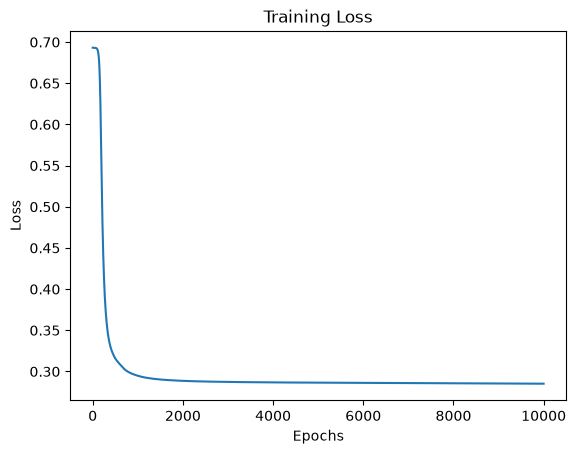

In [11]:
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

### using tensorflow library

In [12]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [13]:
model = Sequential([Dense(3,activation='relu',input_shape=(2,)),
                    Dense(1,activation='sigmoid')

])

/Users/imteyazalam/ml-env/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(

    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.1
    ),

    loss='binary_crossentropy',

    metrics=['accuracy']

)

In [15]:
history = model.fit(

    X_train,
    y_train,

    epochs=10000,

    batch_size=len(X_train),

    verbose=0

)

In [17]:
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 0.2797524631023407
Test Accuracy: 0.8650000095367432


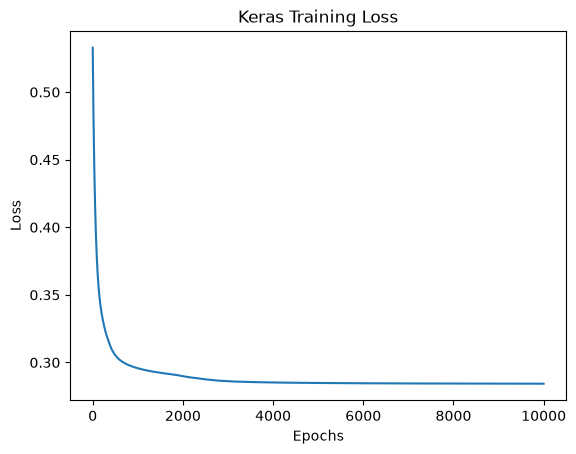

In [18]:
plt.plot(history.history['loss'])

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("Keras Training Loss")

plt.show()